# 03 — Skenario dan Training

Eksperimen utama (**Opsi A**): SVM dilatih hanya dengan **foto asli** dari grup latih (457 citra). Empat skenario fitur × tiga kernel = 12 model. Hyperparameter dipilih dengan *grid search* dan validasi silang 5-fold, memakai `f1_macro` sebagai metrik pemilihan.

Data uji **tidak dibaca** di notebook ini. Semua angka di sini berasal dari validasi silang pada data latih.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
t0 = time.time()

from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from src.features import extract_table, glcm_matrix, lbp_map, scenario_columns
from src.preprocess import preprocess
from src.evaluate import summarize, compare

FIG_DIR = config.FIGURES_DIR / "03_training"
FIG_DIR.mkdir(parents=True, exist_ok=True)
config.FEATURES_DIR.mkdir(exist_ok=True)
split = pd.read_csv(config.RESULTS_DIR / "split.csv")
train = split[split["split"] == "train"].reset_index(drop=True)
print(f"Baris latih: {len(train)} ({(train['aug_type'] == 'original').sum()} foto asli)")

Baris latih: 4113 (457 foto asli)


## 1. Fitur yang diekstrak

**GLCM (Gray-Level Co-occurrence Matrix)** menghitung seberapa sering pasangan intensitas (i, j) muncul pada dua piksel yang berjarak *d* dengan arah tertentu. Citra dikuantisasi dulu ke 8 level, jadi matriksnya 8×8. Dari matriks itu dihitung empat ukuran:

- **kontras**: Σ (i−j)² P(i,j), besar kalau tetangga sering berbeda intensitas;
- **korelasi**: seberapa linear hubungan intensitas piksel dengan tetangganya;
- **energi (ASM)**: Σ P(i,j)², besar kalau teksturnya seragam/berulang;
- **homogenitas**: Σ P(i,j) / (1+|i−j|), besar kalau pasangan piksel cenderung bernilai mirip. Dihitung manual karena `skimage` memakai (i−j)².

S1 memakai sudut 0° saja (tetangga di kanan). S2 merata-ratakan keempat sudut (0°, 45°, 90°, 135°) per jarak. Keduanya 4 ukuran × 3 jarak = 12 fitur.

**LBP (Local Binary Pattern)** membandingkan tiap piksel dengan 8 tetangganya pada jari-jari 1: tetangga yang lebih terang diberi bit 1, lainnya 0, sehingga terbentuk kode 8 bit. Kode *uniform* (paling banyak dua transisi 0↔1, misalnya tepi, sudut, ujung garis) mendapat bin sendiri (58 bin), sedangkan semua kode non-uniform digabung ke satu bin, jadi totalnya 59. Histogram ini dinormalisasi L2. `nri_uniform` tidak invarian rotasi, sama seperti `extractLBPFeatures` MATLAB dengan `Upright=true`.

Gambar di bawah adalah contoh untuk slide: satu foto Puger Galar (data latih), peta LBP-nya, dan matriks GLCM d=1 pada sudut 0° dan 90°.

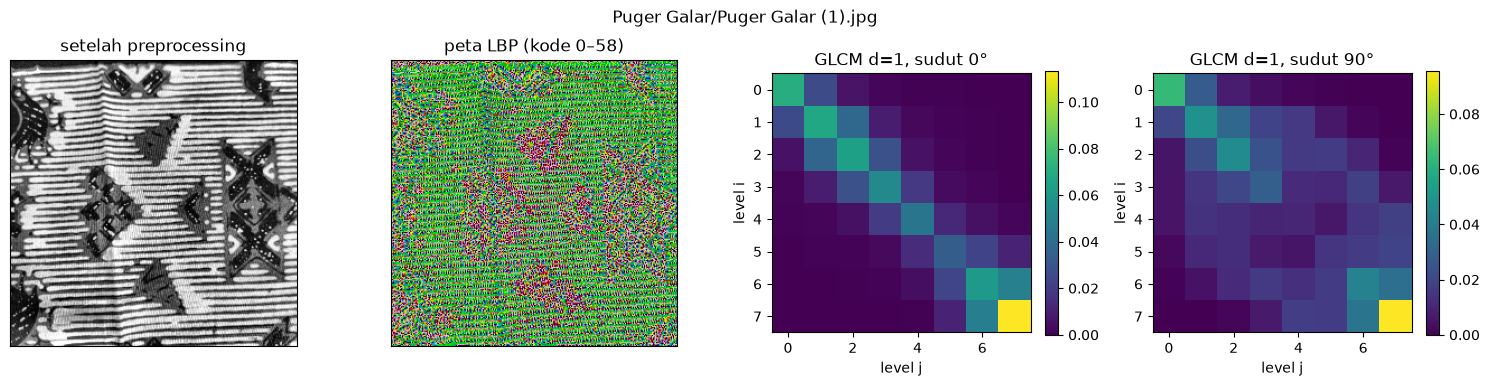

In [2]:
ex_fn = train[(train["label"] == config.H3_CLASS) & (train["aug_type"] == "original")]["filename"].iloc[0]
g = preprocess(config.RAW_DIR / ex_fn)
P = glcm_matrix(g)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
axes[0].imshow(g, cmap="gray"); axes[0].set_title("setelah preprocessing")
axes[1].imshow(lbp_map(g), cmap="nipy_spectral"); axes[1].set_title("peta LBP (kode 0–58)")
for ax, ai, name in [(axes[2], 0, "0°"), (axes[3], 2, "90°")]:
    im = ax.imshow(P[:, :, 0, ai], cmap="viridis")
    ax.set_title(f"GLCM d=1, sudut {name}")
    ax.set_xlabel("level j"); ax.set_ylabel("level i")
    fig.colorbar(im, ax=ax, fraction=0.046)
for ax in axes[:2]:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(ex_fn)
fig.tight_layout()
fig.savefig(FIG_DIR / "contoh_lbp_glcm.png", dpi=150)
plt.show()

## 2. Ekstraksi fitur data latih

Fitur diekstrak untuk **semua** baris latih (foto asli dan augmentasi) supaya cache ini bisa dipakai ulang oleh ablasi Opsi B. Ekstraksi berjalan paralel dan hasilnya disimpan di `features/features_train.csv`. Kalau file cache sudah ada dan barisnya cocok, ekstraksi dilewati.

In [3]:
cache = config.FEATURES_DIR / "features_train.csv"
meta_cols = ["filename", "label", "origin_id", "aug_type", "split"]
if cache.exists() and pd.read_csv(cache, usecols=["filename"])["filename"].tolist() == train["filename"].tolist():
    feats = pd.read_csv(cache)
    print("Memakai cache:", cache.relative_to(config.ROOT))
else:
    t = time.time()
    feats = extract_table(train[meta_cols])
    feats.to_csv(cache, index=False)
    print(f"Ekstraksi {len(feats)} citra: {time.time() - t:.0f} detik")
SCEN = scenario_columns(feats.columns)
print({k: len(v) for k, v in SCEN.items()})

Memakai cache: features\features_train.csv
{'S1': 12, 'S2': 12, 'S3': 59, 'S4': 71}


## 3. Validasi silang

- Data Opsi A: foto asli latih saja.
- `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` dengan `groups=origin_id`. Pada Opsi A tiap `origin_id` hanya punya satu foto, tetapi pengelompokan tetap dipasang supaya skema fold-nya sama dengan Opsi B.
- **Fold yang sama** dipakai untuk semua skenario dan kernel. Dengan begitu perbandingan antar-skenario bersifat berpasangan: tiap skenario diuji pada potongan data yang persis sama.
- `StandardScaler` ada **di dalam** `Pipeline`, jadi scaler hanya di-*fit* pada fold latih, bukan pada seluruh data.

In [4]:
dA = feats[feats["aug_type"] == "original"].reset_index(drop=True)
y, groups = dA["label"].to_numpy(), dA["origin_id"].to_numpy()
cv = StratifiedGroupKFold(n_splits=config.N_FOLDS, shuffle=True, random_state=config.SEED)
folds = list(cv.split(dA, y, groups))
for k, (tr, va) in enumerate(folds):
    print(f"fold {k}: latih {len(tr)}, validasi {len(va)}, per kelas validasi {pd.Series(y[va]).value_counts().min()}–{pd.Series(y[va]).value_counts().max()}")

fold 0: latih 365, validasi 92, per kelas validasi 8–9
fold 1: latih 365, validasi 92, per kelas validasi 8–9
fold 2: latih 366, validasi 91, per kelas validasi 8–9
fold 3: latih 366, validasi 91, per kelas validasi 8–9
fold 4: latih 366, validasi 91, per kelas validasi 8–9


## 4. Grid search 4 skenario × 3 kernel

Grid: `C ∈ {0.1, 1, 10, 100}`; `gamma ∈ {0.001, 0.01, 0.1, 1}` untuk RBF dan polynomial; `degree ∈ {2, 3}` untuk polynomial. Semua memakai `class_weight='balanced'`.

In [5]:
KERNELS = ["linear", "rbf", "poly"]
searches, rows, grid_rows = {}, [], []
t = time.time()
for scen, cols in SCEN.items():
    X = dA[cols].to_numpy()
    for kernel in KERNELS:
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("svc", SVC(kernel=kernel, class_weight="balanced"))])
        gs = GridSearchCV(pipe, config.PARAM_GRIDS[kernel], cv=folds,
                          scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"},
                          refit="f1_macro", n_jobs=-1)
        gs.fit(X, y)
        searches[(scen, kernel)] = gs
        r, b = gs.cv_results_, gs.best_index_
        f1_folds = [r[f"split{k}_test_f1_macro"][b] for k in range(config.N_FOLDS)]
        acc_folds = [r[f"split{k}_test_accuracy"][b] for k in range(config.N_FOLDS)]
        rows.append({
            "scenario": scen, "kernel": kernel, "n_features": len(cols),
            "best_params": {k.replace("svc__", ""): v for k, v in gs.best_params_.items()},
            "f1_macro_mean": np.mean(f1_folds), "f1_macro_std": np.std(f1_folds),
            "accuracy_mean": np.mean(acc_folds), "accuracy_std": np.std(acc_folds),
            **{f"f1_fold{k}": v for k, v in enumerate(f1_folds)},
            **{f"acc_fold{k}": v for k, v in enumerate(acc_folds)},
        })
        g = pd.DataFrame(r["params"]).rename(columns=lambda c: c.replace("svc__", ""))
        g["mean_f1_macro"] = r["mean_test_f1_macro"]
        grid_rows.append(g.assign(scenario=scen, kernel=kernel))
print(f"Grid search selesai: {time.time() - t:.0f} detik")
cvres = pd.DataFrame(rows)
cvres.to_csv(config.RESULTS_DIR / "cv_results.csv", index=False)
pd.concat(grid_rows).to_csv(config.RESULTS_DIR / "cv_grid_full.csv", index=False)

Grid search selesai: 7 detik


Simpangan baku (`std`) dihitung dari 5 skor fold (`np.std`, ddof=0). Dengan hanya 5 fold, selisih yang lebih kecil dari std dianggap **tidak meyakinkan**.

In [6]:
show = cvres[["scenario", "kernel", "n_features", "best_params"]].copy()
show["F1 makro"] = cvres.apply(lambda r: f"{r.f1_macro_mean:.3f} ± {r.f1_macro_std:.3f}", axis=1)
show["akurasi"] = cvres.apply(lambda r: f"{r.accuracy_mean:.3f} ± {r.accuracy_std:.3f}", axis=1)
show

,scenario,kernel,n_features,best_params,F1 makro,akurasi
0,S1,linear,12,{'C': 100},0.927 ± 0.016,0.928 ± 0.015
1,S1,rbf,12,"{'C': 100, 'gamma': 0.1}",0.954 ± 0.007,0.954 ± 0.008
2,S1,poly,12,"{'C': 100, 'degree': 2, 'gamma': 1}",0.930 ± 0.034,0.932 ± 0.032
3,S2,linear,12,{'C': 100},0.980 ± 0.011,0.980 ± 0.011
4,S2,rbf,12,"{'C': 10, 'gamma': 1}",0.973 ± 0.027,0.974 ± 0.026
5,S2,poly,12,"{'C': 10, 'degree': 2, 'gamma': 1}",0.974 ± 0.018,0.974 ± 0.018
6,S3,linear,59,{'C': 1},0.916 ± 0.004,0.915 ± 0.004
7,S3,rbf,59,"{'C': 100, 'gamma': 0.01}",0.938 ± 0.033,0.939 ± 0.031
8,S3,poly,59,"{'C': 0.1, 'degree': 3, 'gamma': 1}",0.892 ± 0.035,0.893 ± 0.035
9,S4,linear,71,{'C': 1},0.950 ± 0.013,0.950 ± 0.013


## 5. Visualisasi hasil validasi silang

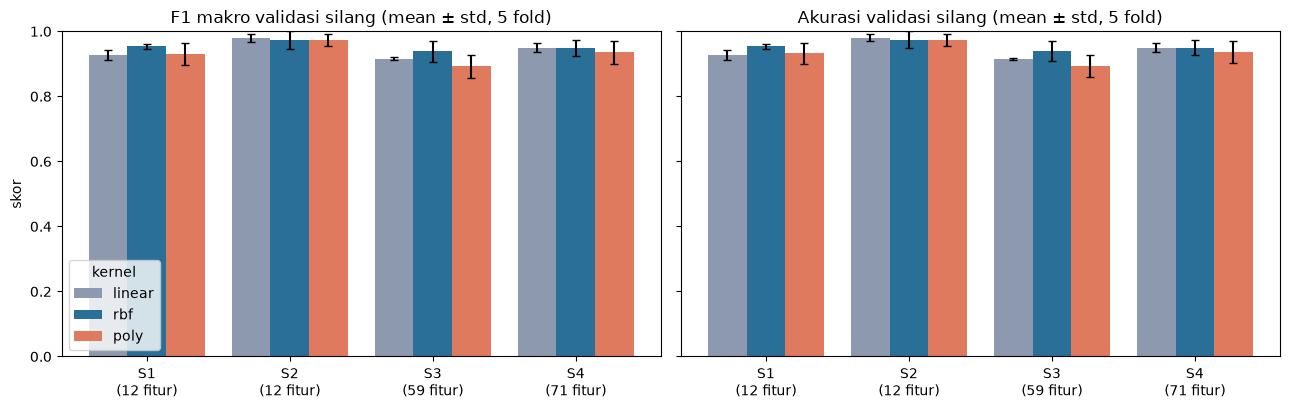

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
colors = {"linear": "#8d99ae", "rbf": "#2a6f97", "poly": "#e07a5f"}
x = np.arange(len(SCEN))
for ax, metric, title in [(axes[0], "f1_macro", "F1 makro"), (axes[1], "accuracy", "Akurasi")]:
    for i, kernel in enumerate(KERNELS):
        sub = cvres[cvres["kernel"] == kernel].set_index("scenario").loc[list(SCEN)]
        ax.bar(x + (i - 1) * 0.27, sub[f"{metric}_mean"], width=0.27, yerr=sub[f"{metric}_std"],
               capsize=3, label=kernel, color=colors[kernel])
    ax.set_xticks(x, [f"{s}\n({len(c)} fitur)" for s, c in SCEN.items()])
    ax.set_title(f"{title} validasi silang (mean ± std, 5 fold)")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("skor"); axes[0].legend(title="kernel")
fig.tight_layout()
fig.savefig(FIG_DIR / "cv_per_skenario_kernel.png", dpi=150)
plt.show()

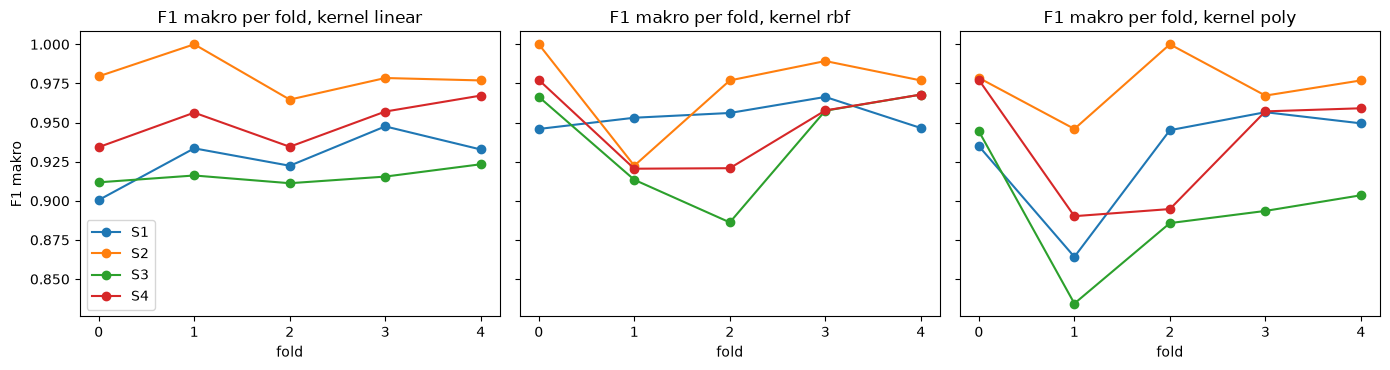

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, kernel in zip(axes, KERNELS):
    for scen in SCEN:
        r = cvres[(cvres["scenario"] == scen) & (cvres["kernel"] == kernel)].iloc[0]
        ax.plot(range(config.N_FOLDS), [r[f"f1_fold{k}"] for k in range(config.N_FOLDS)], marker="o", label=scen)
    ax.set_title(f"F1 makro per fold, kernel {kernel}")
    ax.set_xticks(range(config.N_FOLDS)); ax.set_xlabel("fold")
axes[0].set_ylabel("F1 makro"); axes[0].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "cv_per_fold.png", dpi=150)
plt.show()

Garis per fold memperlihatkan perbandingan berpasangan: kalau satu skenario konsisten di atas skenario lain di hampir semua fold, perbedaannya lebih bisa dipercaya daripada kalau garisnya saling bersilangan.

Heatmap di bawah menunjukkan F1 makro rata-rata untuk tiap kombinasi C × gamma pada kernel RBF.

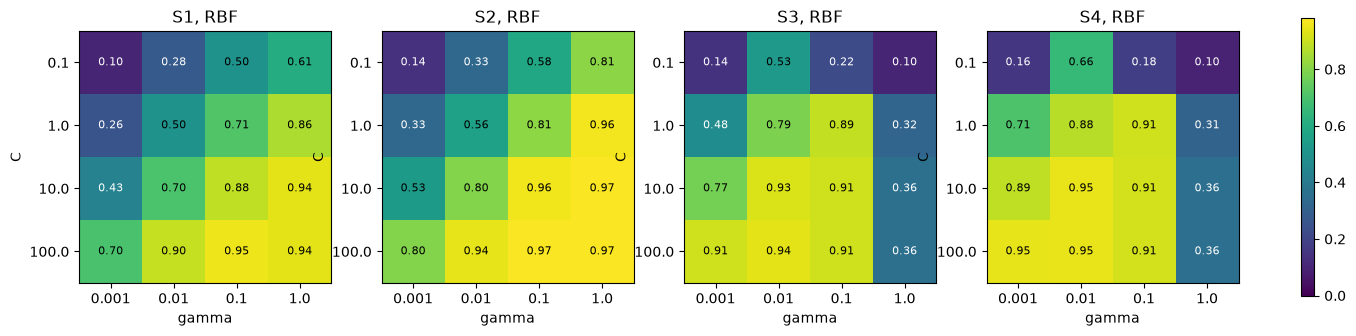

In [9]:
grid = pd.read_csv(config.RESULTS_DIR / "cv_grid_full.csv")
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, scen in zip(axes, SCEN):
    hm = grid[(grid["scenario"] == scen) & (grid["kernel"] == "rbf")].pivot(index="C", columns="gamma", values="mean_f1_macro")
    im = ax.imshow(hm.values, cmap="viridis", vmin=0, vmax=grid["mean_f1_macro"].max())
    ax.set_xticks(range(hm.shape[1]), hm.columns); ax.set_yticks(range(hm.shape[0]), hm.index)
    ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title(f"{scen}, RBF")
    for i in range(hm.shape[0]):
        for j in range(hm.shape[1]):
            ax.text(j, i, f"{hm.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if hm.values[i, j] < 0.5 * grid["mean_f1_macro"].max() else "black")
fig.colorbar(im, ax=axes, fraction=0.015)
fig.savefig(FIG_DIR / "heatmap_rbf.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Recall per kelas dari validasi silang

Untuk H3, recall kelas pantauan (Puger Galar) perlu diamati. Data uji hanya punya sekitar 11 foto Puger Galar, jadi selain di notebook 04, recall juga dihitung dari prediksi *out-of-fold*: tiap foto latih diprediksi oleh model yang **tidak** melihat foto itu saat dilatih (hyperparameter terbaik, fold yang sama). Ini memberi 41 foto Puger Galar sebagai dasar.

In [10]:
oof_rows = []
for (scen, kernel), gs in searches.items():
    pred = cross_val_predict(gs.best_estimator_, dA[SCEN[scen]].to_numpy(), y, cv=folds, n_jobs=-1)
    oof_rows.append({"scenario": scen, "kernel": kernel, **summarize(y, pred)})
oof = pd.DataFrame(oof_rows)
oof.to_csv(config.RESULTS_DIR / "cv_oof_per_class.csv", index=False)
recall = oof.set_index(["scenario", "kernel"])[[f"recall_{c}" for c in config.CLASSES]]
recall.columns = config.CLASSES
recall.round(2)

Angguran  Ayam Puger  Jahe Lumbon  Jahe Puger  Jahe Srimpang  Lumbon  Madu Bronto  Pring Sedapur  Puger Galar  \
scenario kernel                                                                                                                  
S1       linear       1.0        0.95         0.90        0.83           0.93    0.88         1.00           0.85         0.88   
         rbf          1.0        0.98         0.95        0.90           0.93    0.90         0.95           0.90         0.98   
         poly         1.0        0.98         0.79        0.98           0.88    0.88         1.00           0.88         0.90   
S2       linear       1.0        1.00         0.95        0.90           0.95    1.00         1.00           0.98         1.00   
         rbf          1.0        1.00         0.83        1.00           0.93    1.00         1.00           0.95         1.00   
         poly         1.0        1.00         0.88        1.00           0.95    1.00         1.00           0.93         0.95   
S3       linear       1.0        0.98         0.76        0.88           0.93    0.76         1.00           0.85         1.00   
         rbf          1.0        1.00         0.71        0.98           0.90    0.90         1.00           0.88         1.00   
         poly         1.0        1.00         0.64        0.76           0.93    0.76         1.00           0.83         1.00   
S4       linear       1.0        0.95         0.81        0.93           0.90    0.98         1.00           0.88         1.00   
         rbf          1.0        1.00         0.71        0.98           0.90    0.98         1.00           0.88         1.00   
         poly         1.0        1.00         0.71        0.93           0.90    0.98         1.00           0.85         1.00   

                 Puger Telu Bal  Wit Lumbon  
scenario kernel                              
S1       linear            1.00        0.98  
         rbf               1.00        1.00  
         poly              1.00        0.98  
S2       linear            1.00        1.00  
         rbf               1.00        1.00  
         poly              1.00        1.00  
S3       linear            0.95        0.95  
         rbf               0.98        0.98  
         poly              0.98        0.93  
S4       linear            1.00        1.00  
         rbf               1.00        1.00  
         poly              1.00        0.93

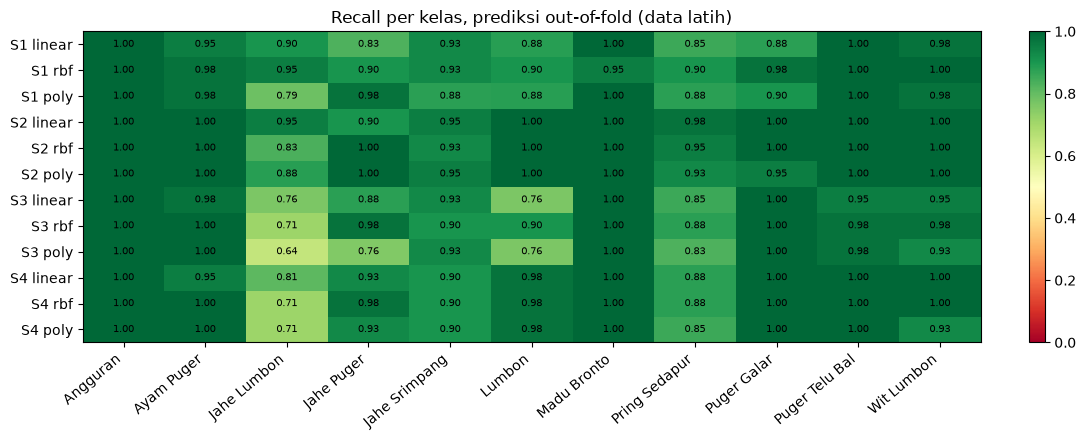

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(recall.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(config.CLASSES)), config.CLASSES, rotation=40, ha="right")
ax.set_yticks(range(len(recall)), [f"{s} {k}" for s, k in recall.index])
for i in range(recall.shape[0]):
    for j in range(recall.shape[1]):
        ax.text(j, i, f"{recall.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Recall per kelas, prediksi out-of-fold (data latih)")
fig.colorbar(im, ax=ax, fraction=0.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "recall_per_kelas_oof.png", dpi=150)
plt.show()

## 7. Ringkasan validasi silang terhadap hipotesis (sementara)

Ini **bukan** kesimpulan akhir. Kesimpulan akhir ada di notebook 04 dan memakai skor validasi silang serta data uji. Aturan status: kalau selisih F1 makro lebih kecil daripada std fold terbesar dari dua model yang dibandingkan, statusnya *tidak meyakinkan*.

Model terbaik per skenario dipilih berdasarkan F1 makro validasi silang tertinggi di antara tiga kernel.

In [12]:
best = cvres.loc[cvres.groupby("scenario")["f1_macro_mean"].idxmax()].set_index("scenario")
cvres["best_in_scenario"] = [best.loc[s, "kernel"] == k for s, k in zip(cvres["scenario"], cvres["kernel"])]
cvres.to_csv(config.RESULTS_DIR / "cv_results.csv", index=False)

def cmp_row(name, ra, rb):
    return {"perbandingan": name,
            "F1 A": f"{ra.f1_macro_mean:.3f} ± {ra.f1_macro_std:.3f}",
            "F1 B": f"{rb.f1_macro_mean:.3f} ± {rb.f1_macro_std:.3f}",
            "selisih": round(ra.f1_macro_mean - rb.f1_macro_mean, 3),
            "status": compare(ra.f1_macro_mean, ra.f1_macro_std, rb.f1_macro_mean, rb.f1_macro_std)}

def row(s, k):
    return cvres[(cvres["scenario"] == s) & (cvres["kernel"] == k)].iloc[0]

h = []
h.append(cmp_row(f"H1: S4 ({best.loc['S4','kernel']}) > S2 ({best.loc['S2','kernel']})", best.loc["S4"], best.loc["S2"]))
h.append(cmp_row(f"H1: S4 ({best.loc['S4','kernel']}) > S3 ({best.loc['S3','kernel']})", best.loc["S4"], best.loc["S3"]))
for s in SCEN:
    nl = max(["rbf", "poly"], key=lambda k: row(s, k).f1_macro_mean)
    h.append(cmp_row(f"H2: {s} {nl} > {s} linear", row(s, nl), row(s, "linear")))
h.append(cmp_row(f"H3: S2 ({best.loc['S2','kernel']}) > S1 ({best.loc['S1','kernel']})", best.loc["S2"], best.loc["S1"]))
hyp_cv = pd.DataFrame(h)
hyp_cv

,perbandingan,F1 A,F1 B,selisih,status
0,H1: S4 (linear) > S2 (linear),0.950 ± 0.013,0.980 ± 0.011,-0.030,tidak didukung
1,H1: S4 (linear) > S3 (rbf),0.950 ± 0.013,0.938 ± 0.033,0.012,tidak meyakinkan
2,H2: S1 rbf > S1 linear,0.954 ± 0.007,0.927 ± 0.016,0.026,didukung
3,H2: S2 poly > S2 linear,0.974 ± 0.018,0.980 ± 0.011,-0.006,tidak meyakinkan
4,H2: S3 rbf > S3 linear,0.938 ± 0.033,0.916 ± 0.004,0.023,tidak meyakinkan
5,H2: S4 rbf > S4 linear,0.949 ± 0.024,0.950 ± 0.013,-0.001,tidak meyakinkan
6,H3: S2 (linear) > S1 (rbf),0.980 ± 0.011,0.954 ± 0.007,0.026,didukung


In [13]:
pg = recall[config.H3_CLASS].unstack("kernel").loc[["S1", "S2"]]
print(f"Recall {config.H3_CLASS} (out-of-fold, data latih):")
print(pg.round(3).to_string())
print()
print("Std F1 makro antar-fold, S1 vs S2 per kernel:")
print(cvres[cvres["scenario"].isin(["S1", "S2"])].pivot(index="scenario", columns="kernel", values="f1_macro_std").round(3).to_string())

Recall Puger Galar (out-of-fold, data latih):
kernel    linear   poly    rbf
scenario                      
S1         0.878  0.902  0.976
S2         1.000  0.951  1.000

Std F1 makro antar-fold, S1 vs S2 per kernel:
kernel    linear   poly    rbf
scenario                      
S1         0.016  0.034  0.007
S2         0.011  0.018  0.027


In [14]:
print(f"Waktu jalan notebook: {time.time() - t0:.0f} detik")

Waktu jalan notebook: 12 detik
